# LFANet-NoAttention Ablation

## 1. Imports

In [1]:
import random
import cv2
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from datetime import datetime
import shutil
from zipfile import ZipFile
from PIL import Image

import tensorflow as tf
import tensorflow.keras.backend as K
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, BatchNormalization, Concatenate, Add, DepthwiseConv2D, GlobalAveragePooling2D, SeparableConv2D, Conv2D, MaxPooling2D, ReLU, Reshape, Softmax, Permute, Lambda
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.utils.multiclass import unique_labels
from tensorflow.keras.utils import to_categorical

## 2. Dataset Loading

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vibhingupta028/liver-histopathology-fibrosis-ultrasound-images")

print("Path to dataset files:", path)

100%|██████████| 205M/205M [00:03<00:00, 65.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/vibhingupta028/liver-histopathology-fibrosis-ultrasound-images/versions/2


## 3. Data Preprocessing & Train/Validation/Test Split

Loaded images from dataset-F0, total: 2114
Loaded images from dataset-F1, total: 861
Loaded images from dataset-F2, total: 793
Loaded images from dataset-F3, total: 857
Loaded images from dataset-F4, total: 1698
Train shape: (4426, 128, 128, 3)
Validation shape: (948, 128, 128, 3)
Test shape: (949, 128, 128, 3)


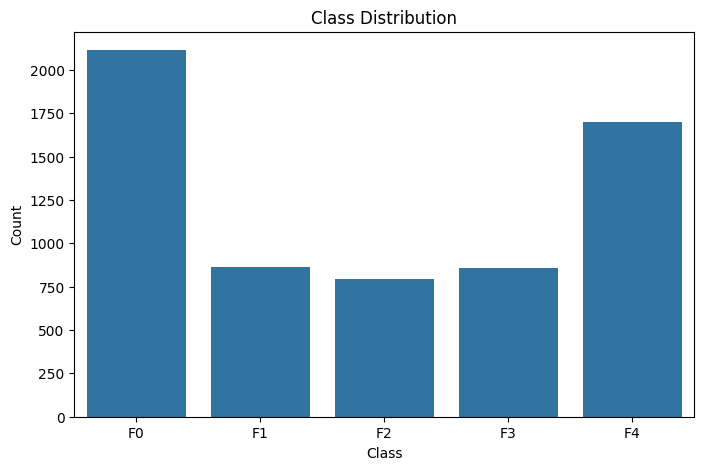

In [3]:
# Define class names
class_names = ['F0', 'F1', 'F2', 'F3', 'F4']
class_to_label = {name: idx for idx, name in enumerate(class_names)}

img_data_list = []
labels = []

# Load images and labels
dataset_path = os.path.join(path, 'Dataset', 'Dataset')
for dataset in class_names:
    img_list = os.listdir(os.path.join(dataset_path, dataset))
    print(f'Loaded images from dataset-{dataset}, total: {len(img_list)}')

    for img in img_list:
        img_path = os.path.join(dataset_path, dataset, img)
        input_img = cv2.imread(img_path)
        if input_img is None:
            continue
        input_img_resize = cv2.resize(input_img, (128, 128))
        img_data_list.append(input_img_resize)
        labels.append(class_to_label[dataset])

# Convert to NumPy arrays and normalize
data = np.array(img_data_list, dtype="float32") / 255.0
labels = np.array(labels)

# One-hot encode labels
num_classes = len(class_names)
labels_one_hot = to_categorical(labels, num_classes)

# Train / temp split (70 / 30)
x_train, x_temp, y_train, y_temp = train_test_split(
    data,
    labels_one_hot,
    test_size=0.3,
    stratify=labels,
    random_state=42
)

# Stratify validation / test split (15 / 15)
y_temp_labels = np.argmax(y_temp, axis=1)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp_labels,
    random_state=42
)

# Shuffle
x_train, y_train = shuffle(x_train, y_train, random_state=42)
x_val, y_val = shuffle(x_val, y_val, random_state=42)
x_test, y_test = shuffle(x_test, y_test, random_state=42)

# Reshape for model input
x_train = x_train.reshape(-1, 128, 128, 3)
x_val = x_val.reshape(-1, 128, 128, 3)
x_test = x_test.reshape(-1, 128, 128, 3)

# Confirm shapes
print("Train shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)

# Plot class distribution
plt.figure(figsize=(8, 5))
sns.countplot(x=np.argmax(labels_one_hot, axis=1))
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(ticks=range(num_classes), labels=class_names)
plt.show()

## 4. LFANet-NoAttention Model Definition

In [4]:
METRICS = [tf.keras.metrics.CategoricalAccuracy(name='accuracy'),
           tf.keras.metrics.Precision(name='precision'),
           tf.keras.metrics.Recall(name='recall'),
           tf.keras.metrics.AUC(name='auc')]

# Input Layer
input_layer_no_attention = tf.keras.Input(shape=(128, 128, 3), name='input_no_attention')

# Initial Convolution Block
x_no_attention = Conv2D(32, (3, 3), strides=(2, 2), padding='same', activation='relu', name='conv2d_initial_no_attention')(input_layer_no_attention)
x_no_attention = BatchNormalization(name='bn_initial_no_attention')(x_no_attention)
x_no_attention = Conv2D(64, (3, 3), padding='same', activation='relu', name='conv2d_64_no_attention')(x_no_attention)
x_no_attention = BatchNormalization(name='bn_64_no_attention')(x_no_attention)

# Depthwise Separable Convolution Block
x_no_attention = DepthwiseConv2D((3, 3), padding='same', strides=(1, 1), name='depthwise_conv2d_first_no_attention')(x_no_attention)
x_no_attention = BatchNormalization(name='bn_dw_first_no_attention')(x_no_attention)
x_no_attention = ReLU(name='relu_dw_first_no_attention')(x_no_attention)

# Dilated Convolution Branches for Multi-scale Features
x1_no_attention = Conv2D(128, (3, 3), dilation_rate=1, padding='same', activation='relu', name='conv2d_dilated1_no_attention')(x_no_attention)
x1_no_attention = BatchNormalization(name='bn_dilated1_no_attention')(x1_no_attention)
x2_no_attention = Conv2D(128, (3, 3), dilation_rate=3, padding='same', activation='relu', name='conv2d_dilated2_no_attention')(x_no_attention)
x2_no_attention = BatchNormalization(name='bn_dilated2_no_attention')(x2_no_attention)
x3_no_attention = Conv2D(128, (3, 3), dilation_rate=5, padding='same', activation='relu', name='conv2d_dilated3_no_attention')(x_no_attention)
x3_no_attention = BatchNormalization(name='bn_dilated3_no_attention')(x3_no_attention)

# Adding Branch Outputs
A1_no_attention = Add(name='add_dilated_no_attention')([x1_no_attention, x2_no_attention, x3_no_attention])

# Intermediate Convolutional Block
x4_no_attention = Conv2D(128, (3, 3), padding='same', activation='relu', name='conv2d_intermediate_no_attention')(A1_no_attention)
x4_no_attention = BatchNormalization(name='bn_intermediate_no_attention')(x4_no_attention)

# --- Ablation: Removed self_attention module, direct pass-through ---
x_no_attention = x4_no_attention
# -------------------------------------------------------------------

# Concatenation Block
C1_no_attention = Concatenate(name='concat_c1_no_attention')([x_no_attention, x2_no_attention, x3_no_attention])
x5_no_attention = Conv2D(128, (3, 3), padding='same', activation='relu', name='conv2d_c1_no_attention')(C1_no_attention)

# Residual Connection
C2_no_attention = Concatenate(name='concat_c2_no_attention')([x5_no_attention, x_no_attention])
x_no_attention = Conv2D(256, (3, 3), padding='same', activation='relu', name='conv2d_c2_no_attention')(C2_no_attention)
x_no_attention = BatchNormalization(name='bn_c2_no_attention')(x_no_attention)

# Expanded Depthwise Separable Convolution Block
x_no_attention = DepthwiseConv2D((3, 3), padding='same', strides=(1, 1), name='depthwise_conv2d_second_no_attention')(x_no_attention)
x_no_attention = BatchNormalization(name='bn_dw_second_no_attention')(x_no_attention)
x_no_attention = ReLU(name='relu_dw_second_no_attention')(x_no_attention)
x_no_attention = Conv2D(256, (1, 1), padding='same', activation='relu', name='conv2d_1x1_no_attention')(x_no_attention)
x_no_attention = BatchNormalization(name='bn_1x1_no_attention')(x_no_attention)

# Additional Residual Connection
residual_no_attention = Conv2D(256, (1, 1), padding='same', activation='relu', name='conv2d_residual_no_attention')(C2_no_attention)
x_no_attention = Add(name='add_residual_no_attention')([x_no_attention, residual_no_attention])

# Further Convolutional Layers
x_no_attention = Conv2D(256, (3, 3), padding='same', activation='relu', name='conv2d_256_no_attention')(x_no_attention)
x_no_attention = BatchNormalization(name='bn_256_no_attention')(x_no_attention)
x_no_attention = Conv2D(512, (3, 3), padding='same', activation='relu', name='conv2d_512_no_attention')(x_no_attention)
x_no_attention = BatchNormalization(name='bn_512_no_attention')(x_no_attention)

# Global Pooling
x_no_attention = GlobalAveragePooling2D(name='global_avg_pooling_no_attention')(x_no_attention)

# Fully Connected Layers
x_no_attention = Dense(512, activation='relu', name='dense_512_no_attention')(x_no_attention)
x_no_attention = Dense(256, activation='relu', name='dense_256_no_attention')(x_no_attention)
output_no_attention = Dense(num_classes, activation='softmax', name='output_no_attention')(x_no_attention)

# Model Compilation
model_no_attention = Model(inputs=input_layer_no_attention, outputs=output_no_attention, name='LFANet_NoAttention')
model_no_attention.compile(optimizer='adam', loss='categorical_crossentropy', metrics=METRICS)

## 5. Model Summary & Parameter Count

In [5]:
print("LFANet-NoAttention Model Summary:")
model_no_attention.summary()

# Parameter count
total_params = model_no_attention.count_params()
trainable_params = sum([K.count_params(w) for w in model_no_attention.trainable_weights])
non_trainable_params = sum([K.count_params(w) for w in model_no_attention.non_trainable_weights])

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

LFANet-NoAttention Model Summary:


Model: "LFANet_NoAttention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_no_attention  │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_initial_no_… │ (None, 64, 64,    │        896 │ input_no_attenti… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_initial_no_atte… │ (None, 64, 64,    │        128 │ conv2d_initial_n… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_64_no_atten… │ (None, 64, 64,    │     18,496 │ bn_initial_no_at… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_64_no_attention  │ (None, 64, 64,    │        256 │ conv2d_64_no_att… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_f… │ (None, 64, 64,    │        640 │ bn_64_no_attenti… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_dw_first_no_att… │ (None, 64, 64,    │        256 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu_dw_first_no_a… │ (None, 64, 64,    │          0 │ bn_dw_first_no_a… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_dilated1_no… │ (None, 64, 64,    │     73,856 │ relu_dw_first_no… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_dilated2_no… │ (None, 64, 64,    │     73,856 │ relu_dw_first_no… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_dilated3_no… │ (None, 64, 64,    │     73,856 │ relu_dw_first_no… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_dilated1_no_att… │ (None, 64, 64,    │        512 │ conv2d_dilated1_… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_dilated2_no_att… │ (None, 64, 64,    │        512 │ conv2d_dilated2_… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_dilated3_no_att… │ (None, 64, 64,    │        512 │ conv2d_dilated3_… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_dilated_no_att… │ (None, 64, 64,    │          0 │ bn_dilated1_no_a… │
│ (Add)               │ 128)              │            │ bn_dilated2_no_a… │
│                     │                   │            │ bn_dilated3_no_a… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_intermediat… │ (None, 64, 64,    │    147,584 │ add_dilated_no_a… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 3,730,245 (14.23 MB)

 Trainable params: 3,725,829 (14.21 MB)

 Non-trainable params: 4,416 (17.25 KB)


Total parameters: 3,730,245
Trainable parameters: 3,725,829
Non-trainable parameters: 4,416


## 6. Callbacks

In [6]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

checkpoint_no_attention = ModelCheckpoint(
    filepath='model_no_attention-{epoch:03d}-{accuracy:.3f}-{val_accuracy:.3f}.keras',
    verbose=1,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

callbacks_list = [early_stop, lr_scheduler, checkpoint_no_attention]
print("Callbacks defined: EarlyStopping, ReduceLROnPlateau, ModelCheckpoint.")

Callbacks defined: EarlyStopping, ReduceLROnPlateau, ModelCheckpoint.


## 7. Training

In [7]:
print("Starting training for LFANet-NoAttention...")
start_train_no_attention = time.time()
history_no_attention = model_no_attention.fit(x_train, y_train, batch_size = 16, epochs = 50,
                    validation_data = (x_val , y_val), callbacks=callbacks_list, verbose =1)
end_train_no_attention = time.time()
training_time_no_attention = end_train_no_attention - start_train_no_attention
print(f"\nTraining time for LFANet-NoAttention: {training_time_no_attention:.2f} seconds")

Starting training for LFANet-NoAttention...
Epoch 1/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.5136 - auc: 0.8368 - loss: 1.0891 - precision: 0.6856 - recall: 0.3523
Epoch 1: val_accuracy improved from None to 0.26899, saving model to model_no_attention-001-0.559-0.269.keras

Epoch 1: finished saving model to model_no_attention-001-0.559-0.269.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 154s 405ms/step - accuracy: 0.5590 - auc: 0.8704 - loss: 0.9651 - precision: 0.7596 - recall: 0.4092 - val_accuracy: 0.2690 - val_auc: 0.4975 - val_loss: 7.8624 - val_precision: 0.2690 - val_recall: 0.2690 - learning_rate: 0.0010
Epoch 2/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.6432 - auc: 0.9163 - loss: 0.7623 - precision: 0.8685 - recall: 0.5090
Epoch 2: val_accuracy improved from 0.26899 to 0.33861, saving model to model_no_attention-002-0.666-0.339.keras

Epoch 2: finished saving model to model_no_attention-002-0.666-0.339.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 66s 237ms/step 

## 8. Evaluation, Confusion Matrix, and ROC Curves

In [8]:
# The EarlyStopping callback with restore_best_weights=True handles loading the best weights automatically.

loss_no_attention, acc_no_attention, prec_no_attention, rec_no_attention, auc_no_attention = model_no_attention.evaluate(x_test, y_test, verbose=0)
print(f"\nLFANet-NoAttention Test Loss: {loss_no_attention:.4f}")
print(f"LFANet-NoAttention Test Accuracy: {acc_no_attention:.4f}")
print(f"LFANet-NoAttention Test Precision: {prec_no_attention:.4f}")
print(f"LFANet-NoAttention Test Recall: {rec_no_attention:.4f}")
print(f"LFANet-NoAttention Test AUC: {auc_no_attention:.4f}")

# Get predicted probabilities and predicted class labels for LFANet-NoAttention
y_pred_no_attention = model_no_attention.predict(x_test)
y_pred_classes_no_attention = np.argmax(y_pred_no_attention, axis=1);

# Convert one-hot encoded y_test back to class labels
y_true = np.argmax(y_test, axis=1)

# Define class labels explicitly to ensure consistent ordering
labels = np.arange(num_classes)

# Create confusion matrix
conf_matrix_no_attention = confusion_matrix(y_true, y_pred_classes_no_attention, labels=labels)

# Compute class-wise metrics from sklearn report
report_no_attention = classification_report(y_true, y_pred_classes_no_attention, output_dict=True, labels=labels)

# Compute specificity, PLR, and NLR for each class
specificity_no_attention = {}
plr_no_attention = {}
nlr_no_attention = {}

print("\nLFANet-NoAttention Class-wise metrics:")
for i in labels:
    tp = conf_matrix_no_attention[i, i]
    fn = np.sum(conf_matrix_no_attention[i, :]) - tp
    fp = np.sum(conf_matrix_no_attention[:, i]) - tp
    tn = np.sum(conf_matrix_no_attention) - (tp + fp + fn)

    sens = tp / (tp + fn) if (tp + fn) > 0 else 0  # Sensitivity (Recall)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0  # Specificity

    specificity_no_attention[i] = spec
    # Positive Likelihood Ratio (PLR) = Sensitivity / (1 - Specificity)
    plr_no_attention[i] = sens / (1 - spec) if (1 - spec) > 0 else np.inf
    # Negative Likelihood Ratio (NLR) = (1 - Sensitivity) / Specificity
    nlr_no_attention[i] = (1 - sens) / spec if spec > 0 else np.inf

    print(f"Class {i}:")
    print(f"  Precision   : {report_no_attention[str(i)]['precision']:.4f}")
    print(f"  Recall      : {report_no_attention[str(i)]['recall']:.4f}")
    print(f"  Specificity : {specificity_no_attention[i]:.4f}")
    print(f"  PLR         : {plr_no_attention[i]:.4f}")
    print(f"  NLR         : {nlr_no_attention[i]:.4f}")
    print(f"  F1-Score    : {report_no_attention[str(i)]['f1-score']:.4f}")
    print()


LFANet-NoAttention Test Loss: 0.1357
LFANet-NoAttention Test Accuracy: 0.9621
LFANet-NoAttention Test Precision: 0.9661
LFANet-NoAttention Test Recall: 0.9621
LFANet-NoAttention Test AUC: 0.9947
30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 222ms/step

LFANet-NoAttention Class-wise metrics:
Class 0:
  Precision   : 1.0000
  Recall      : 1.0000
  Specificity : 1.0000
  PLR         : inf
  NLR         : 0.0000
  F1-Score    : 1.0000

Class 1:
  Precision   : 0.9573
  Recall      : 0.8682
  Specificity : 0.9939
  PLR         : 142.3876
  NLR         : 0.1326
  F1-Score    : 0.9106

Class 2:
  Precision   : 0.9060
  Recall      : 0.8908
  Specificity : 0.9867
  PLR         : 67.2116
  NLR         : 0.1107
  F1-Score    : 0.8983

Class 3:
  Precision   : 0.9111
  Recall      : 0.9535
  Specificity : 0.9854
  PLR         : 65.1550
  NLR         : 0.0472
  F1-Score    : 0.9318

Class 4:
  Precision   : 0.9696
  Recall      : 1.0000
  Specificity : 0.9885
  PLR         : 86.7500
  NLR         : 0.0000
  F1-

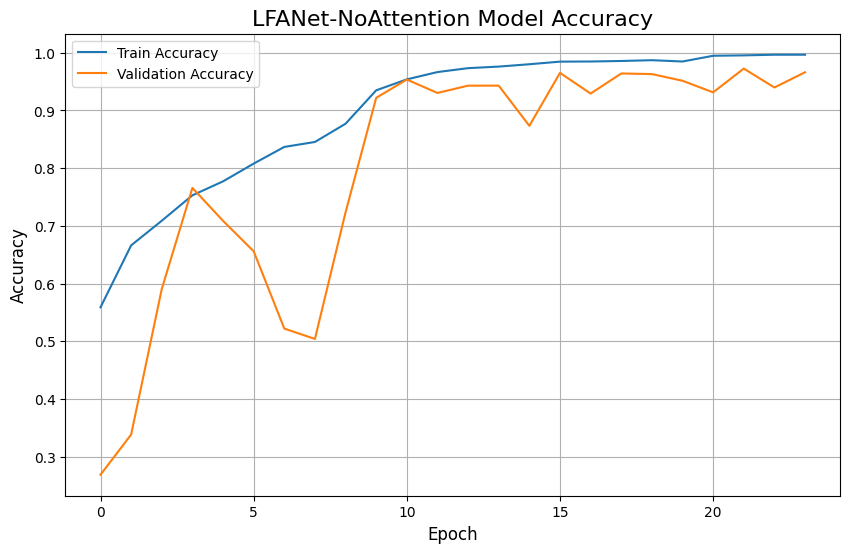

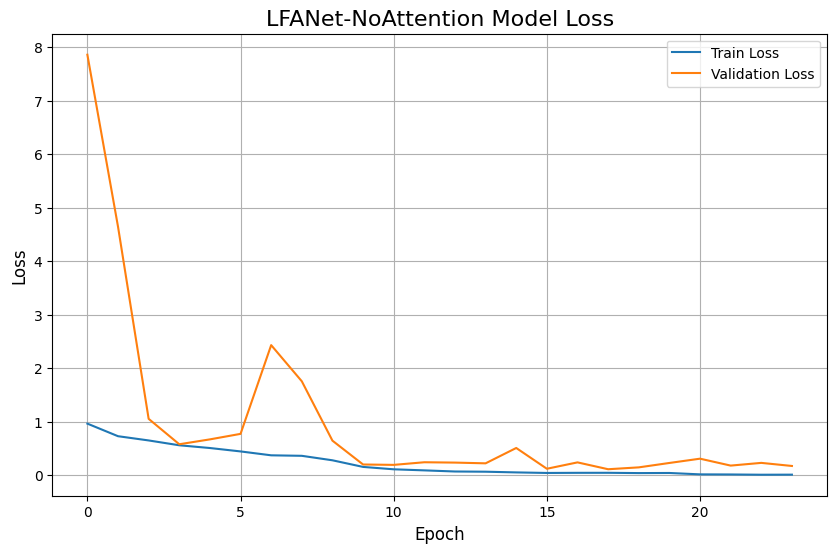

In [9]:
def plot_accuracy(history, title="Model Accuracy"):
    plt.figure(figsize=(10, 6))
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(title, fontsize=16)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_loss(history, title="Model Loss"):
    plt.figure(figsize=(10, 6))
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(title, fontsize=16)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True)
    plt.show()

plot_accuracy(history_no_attention, title='LFANet-NoAttention Model Accuracy')
plot_loss(history_no_attention, title='LFANet-NoAttention Model Loss')

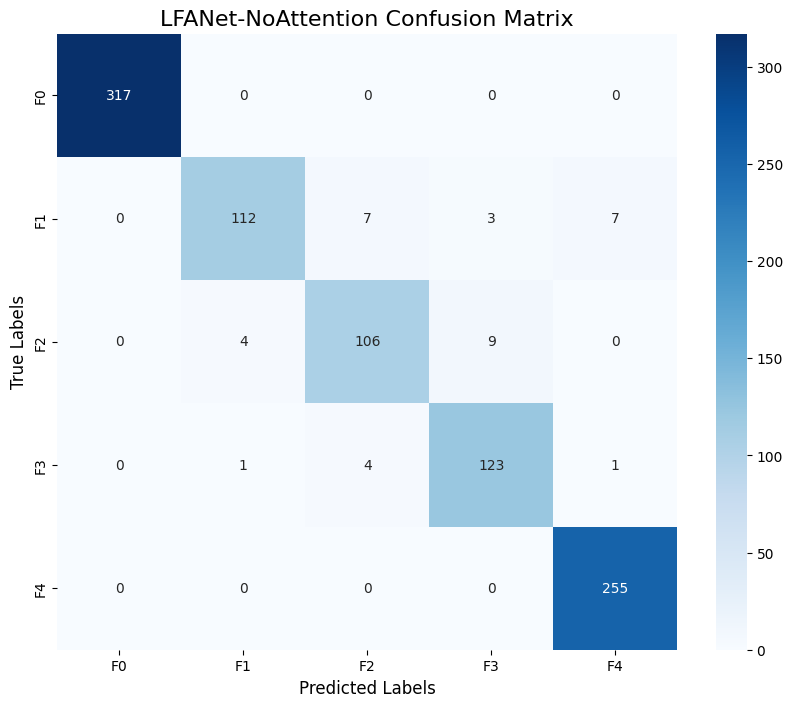

In [10]:
# Plot confusion matrix using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix_no_attention, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('LFANet-NoAttention Confusion Matrix', fontsize=16)
plt.xlabel('Predicted Labels', fontsize=12)
plt.ylabel('True Labels', fontsize=12)
plt.show()

/tmp/ipykernel_1071/2935955385.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", num_classes)


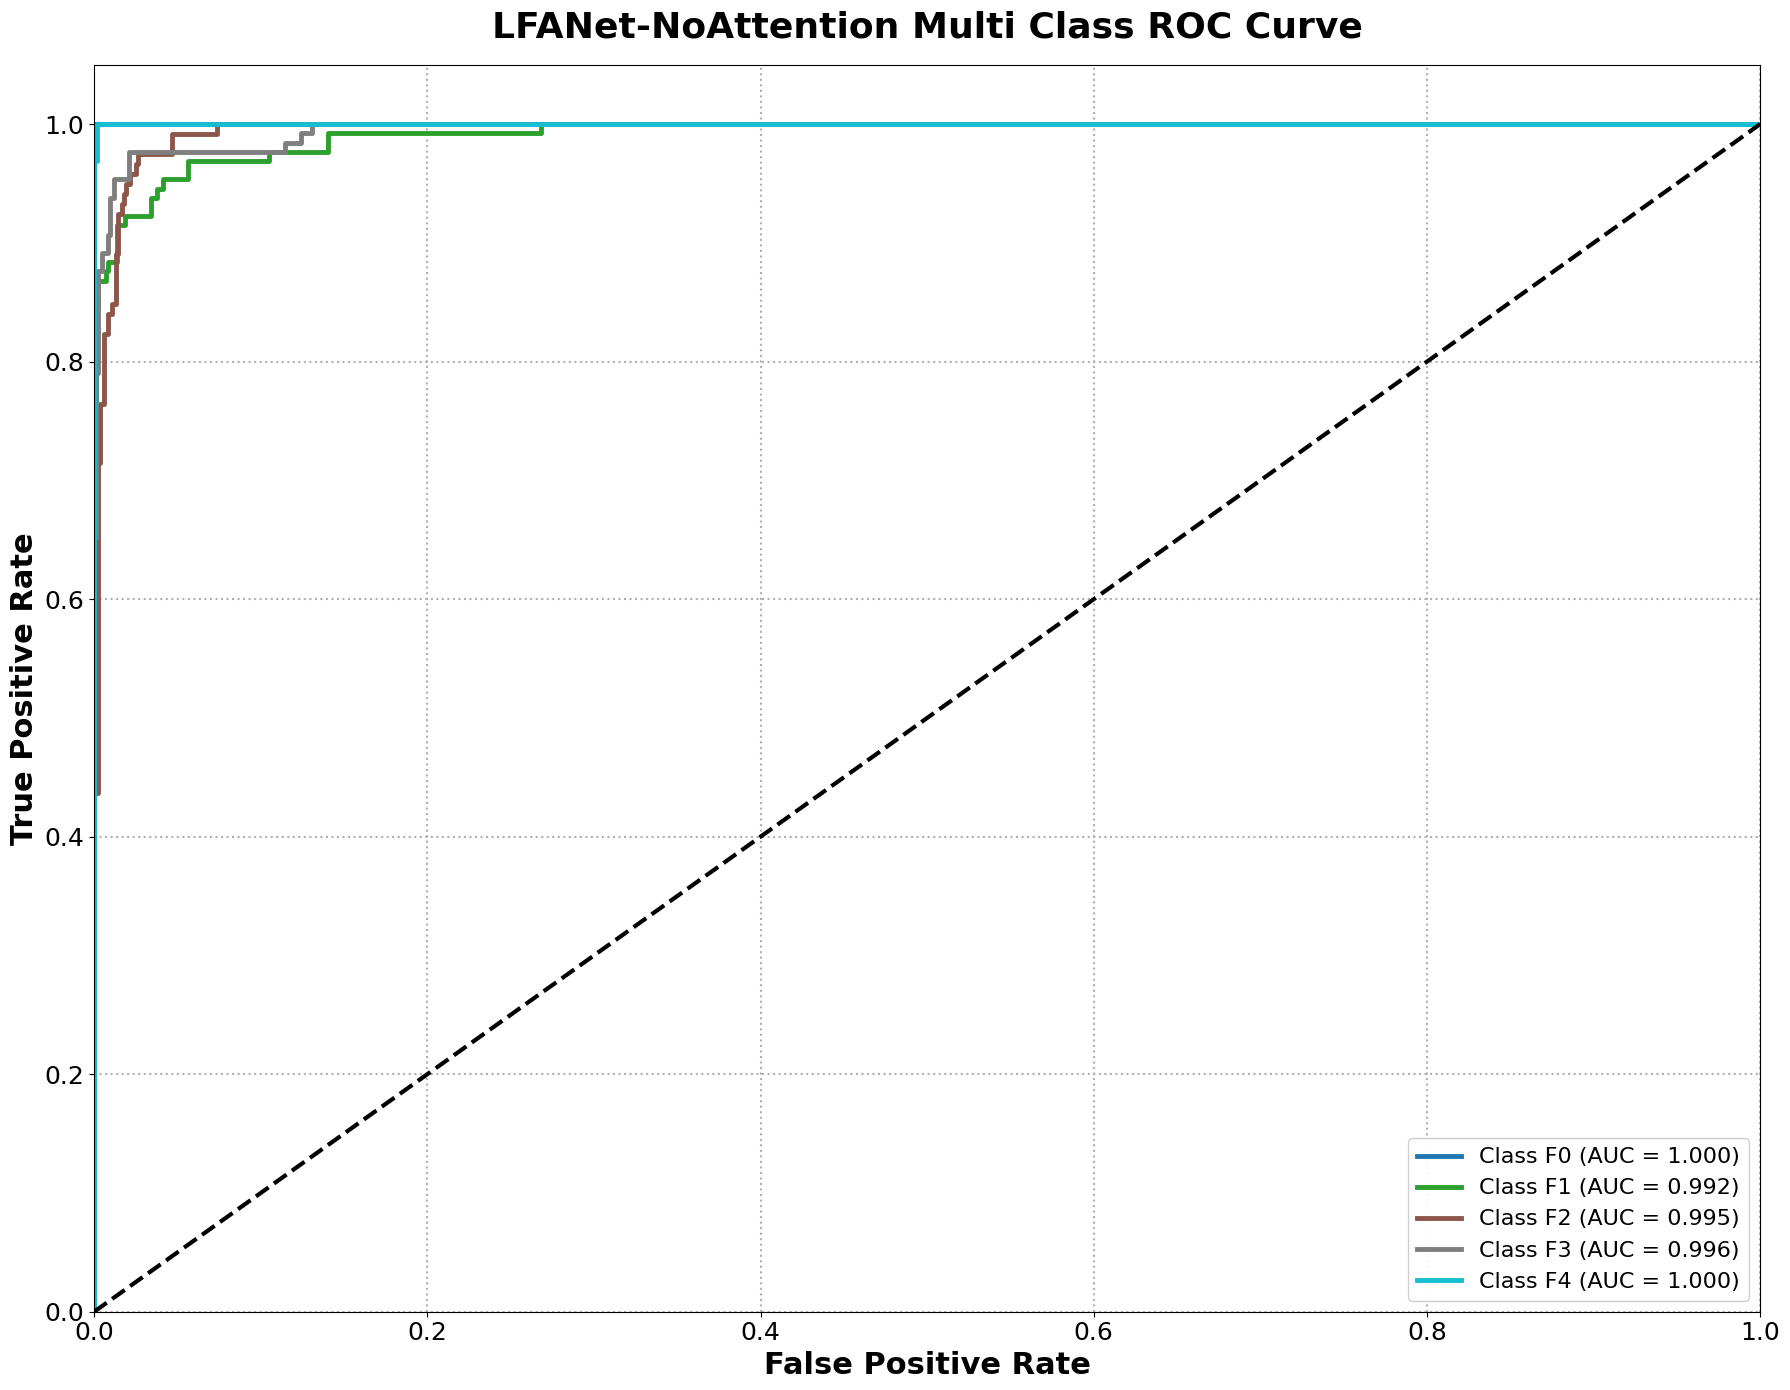

In [11]:
# Binarize labels
y_true_bin = label_binarize(y_true, classes=np.arange(num_classes))

# ROC computation for LFANet-NoAttention
fpr_no_attention, tpr_no_attention, roc_auc_no_attention = {}, {}, {}
for i in range(num_classes):
    fpr_no_attention[i], tpr_no_attention[i], _ = roc_curve(y_true_bin[:, i], y_pred_no_attention[:, i])
    roc_auc_no_attention[i] = auc(fpr_no_attention[i], tpr_no_attention[i])

# Plot
plt.figure(figsize=(18, 14))

colors = plt.cm.get_cmap("tab10", num_classes)

for i in range(num_classes):
    plt.plot(
        fpr_no_attention[i],
        tpr_no_attention[i],
        linewidth=3.5,
        color=colors(i),
        label=f"Class {class_names[i]} (AUC = {roc_auc_no_attention[i]:.3f})"
    )

# Reference line
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=3, color="black")

# Axis limits
plt.xlim(0, 1)
plt.ylim(0, 1.05)

# Labels and title (large and clear)
plt.xlabel("False Positive Rate", fontsize=22, fontweight="bold")
plt.ylabel("True Positive Rate", fontsize=22, fontweight="bold")
plt.title("LFANet-NoAttention Multi Class ROC Curve", fontsize=26, fontweight="bold", pad=20)

# Ticks
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Legend
plt.legend(
    loc="lower right",
    fontsize=16,
    frameon=True,
    framealpha=0.95
)

# Grid for readability
plt.grid(True, linestyle=":", linewidth=1.5)

plt.tight_layout()
plt.show()

## 9. Inference Time

In [12]:
start_inf_no_attention = time.time()
_ = model_no_attention.predict(x_test) # Warm-up run
end_warmup_no_attention = time.time()

start_inf_no_attention = time.time()
preds_no_attention = model_no_attention.predict(x_test)
end_inf_no_attention = time.time()

inference_time_no_attention = end_inf_no_attention - start_inf_no_attention
msec_per_image_no_attention = (inference_time_no_attention / len(x_test)) * 1000

print(f"\nLFANet-NoAttention Inference time on test set: {inference_time_no_attention:.4f} seconds")
print(f"LFANet-NoAttention Milliseconds per image: {msec_per_image_no_attention:.4f} ms")

30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 167ms/step
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 169ms/step

LFANet-NoAttention Inference time on test set: 5.5181 seconds
LFANet-NoAttention Milliseconds per image: 5.8146 ms


## 10. Model Size

In [13]:
temp_keras_path = "temp_model_no_attention_size.keras"
model_no_attention.save(temp_keras_path)
model_size_mb_no_attention = os.path.getsize(temp_keras_path) / (1024 * 1024)
os.remove(temp_keras_path)
print(f"LFANet-NoAttention Model size: {model_size_mb_no_attention:.4f} MB")

LFANet-NoAttention Model size: 42.8421 MB


## 11. Grad-CAM

Using last convolutional layer for Grad-CAM: conv2d_512_no_attention
Generating 20 Grad-CAM images...


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_no_attention']]
Received: inputs=['Tensor(shape=(1, 128, 128, 3))']
  warnings.warn(msg)


Saved 20 Grad-CAM images to 'gradcam_outputs_no_attention'
Grad-CAM images zipped into 'gradcams_no_attention.zip'

Displaying 5 sample Grad-CAMs:


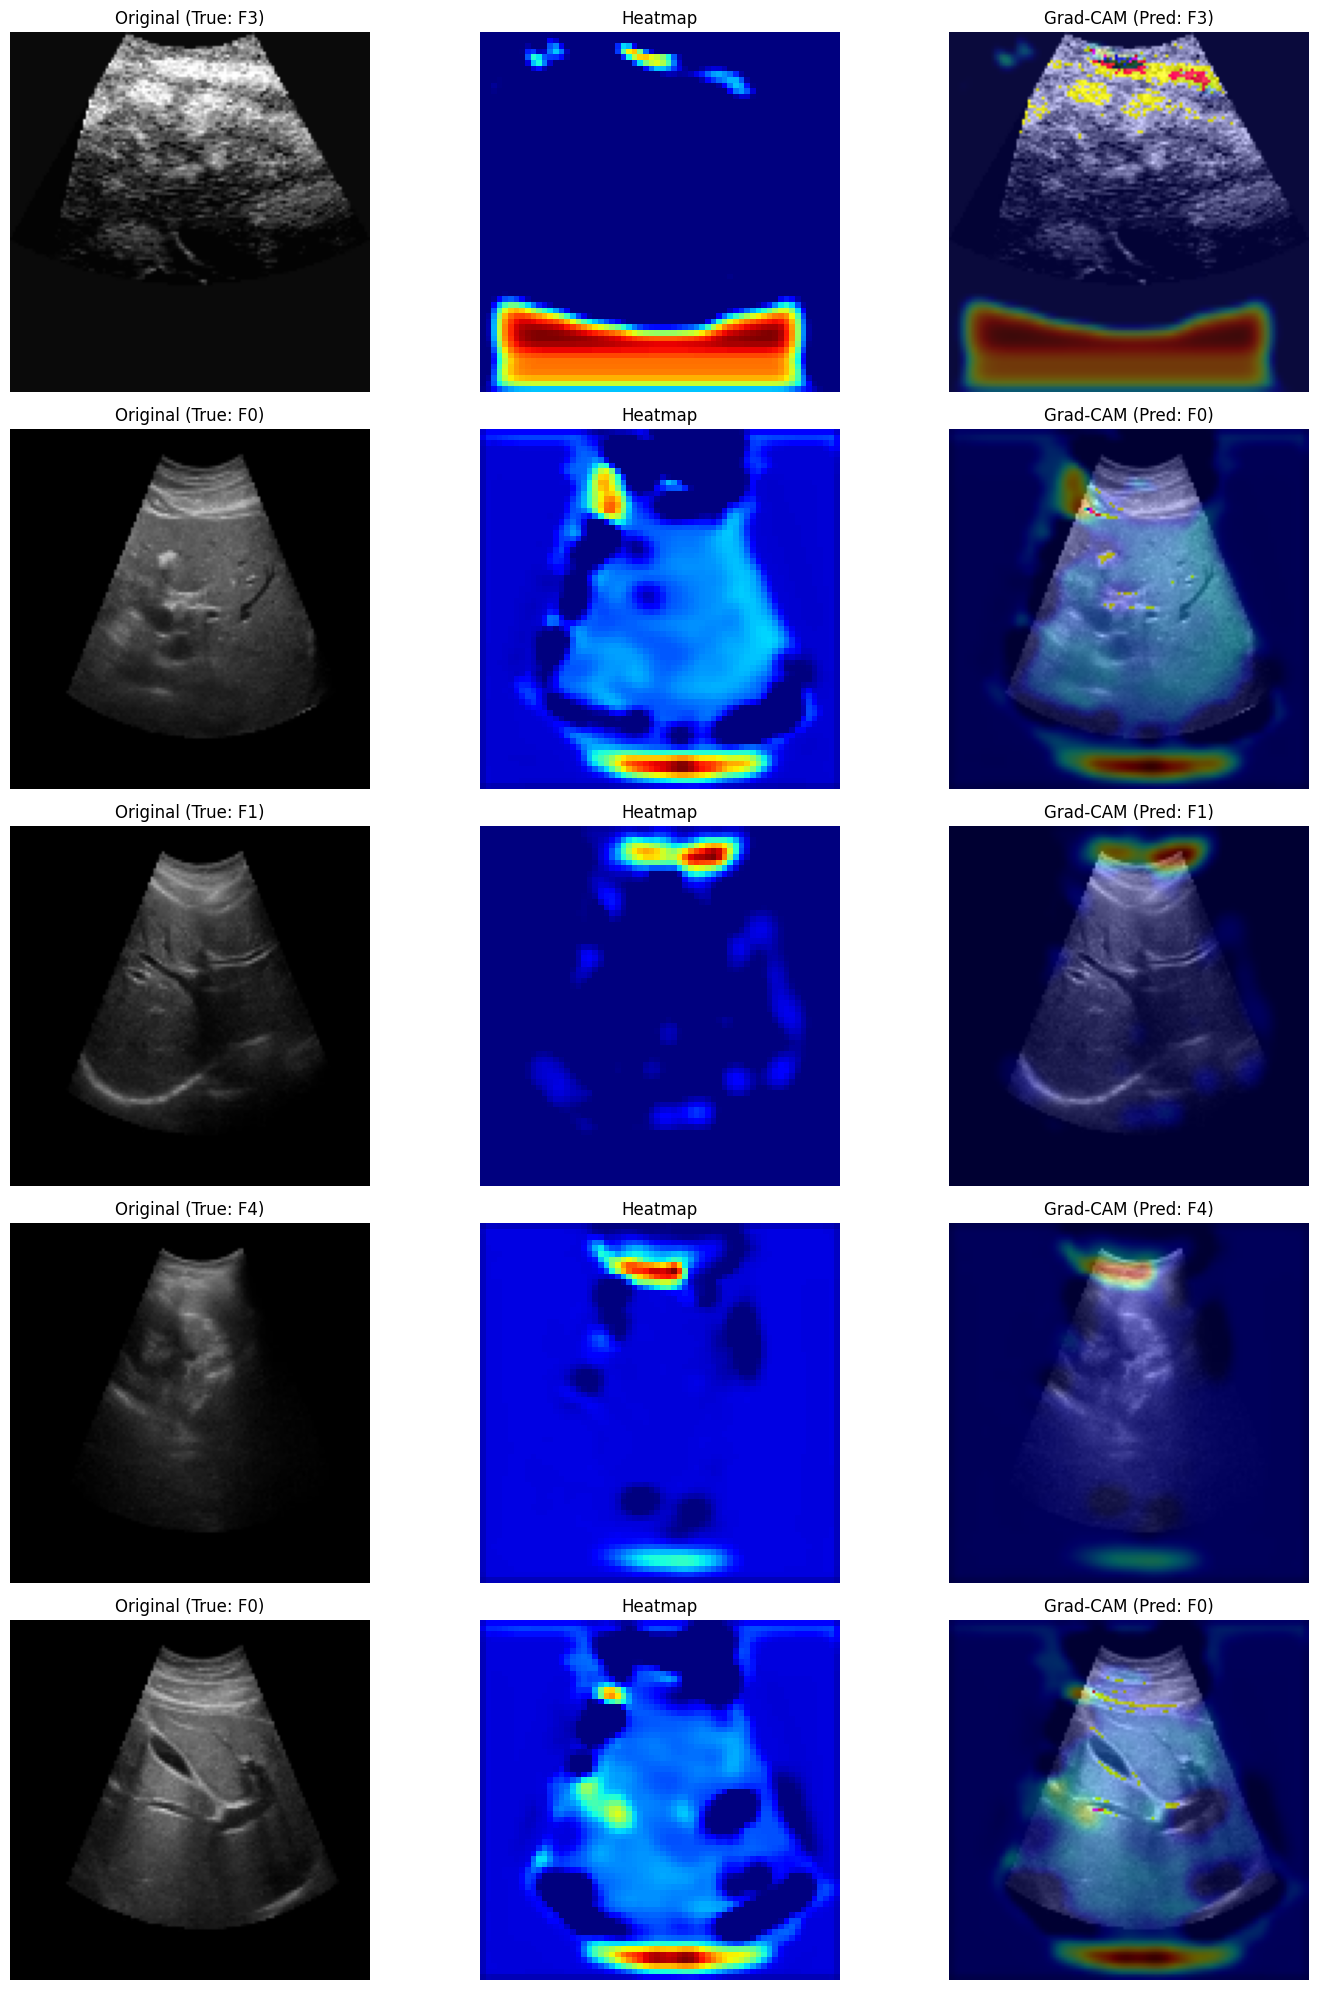

In [14]:
def find_last_conv_layer(model):
    for layer in reversed(model.layers):
        if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.DepthwiseConv2D, tf.keras.layers.SeparableConv2D)):
            # Exclude 1x1 conv layers that might be used for feature projection
            if '1x1' not in layer.name and layer.kernel_size[0] > 1:
                return layer.name
            # If it's a 1x1 conv, check if it's the last meaningful one
            if layer.kernel_size[0] == 1 and layer.name.endswith('_no_attention'): # Heuristic for this specific model
                 return layer.name
    raise ValueError("No suitable convolutional layer found in the model for Grad-CAM.")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = tf.einsum('ijc,c->ij', conv_outputs, pooled_grads)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy(), int(pred_index)

def get_img_array_from_tensor(img_tensor, size):
    img = tf.image.resize(img_tensor, size)
    img = tf.expand_dims(img, axis=0)
    return img

def save_and_display_gradcam_overlay(image, heatmap, alpha=0.4):
    heatmap = np.uint8(255 * heatmap)
    cmap = plt.get_cmap("jet")
    jet_colors = cmap(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    jet_heatmap = Image.fromarray((jet_heatmap * 255).astype(np.uint8))
    jet_heatmap = jet_heatmap.resize((image.shape[1], image.shape[0]), Image.BILINEAR)
    jet_heatmap = np.array(jet_heatmap)

    superimposed_img = jet_heatmap * alpha + image
    superimposed_img = np.uint8(superimposed_img)
    return superimposed_img


# --- CONFIGURATION FOR GRAD-CAM ---
output_dir = "gradcam_outputs_no_attention"
zip_filename = "gradcams_no_attention.zip"
img_size = (128, 128)
max_images_to_process = 20  # Process a subset for demonstration/efficiency
max_images_to_display = 5 # Display a smaller subset visually

# Dynamically find the last convolutional layer
try:
    last_conv_layer_name = find_last_conv_layer(model_no_attention)
    print(f"Using last convolutional layer for Grad-CAM: {last_conv_layer_name}")
except ValueError as e:
    print(e)
    print("Grad-CAM cannot proceed without a suitable convolutional layer.")
    last_conv_layer_name = None

if last_conv_layer_name:
    os.makedirs(output_dir, exist_ok=True)
    all_gradcam_files = []

    # --- Generate and save all Grad-CAMs ---
    print(f"Generating {min(max_images_to_process, len(x_test))} Grad-CAM images...")
    for idx in range(min(max_images_to_process, len(x_test))):
        img = x_test[idx]
        true_label = np.argmax(y_test[idx]) if y_test.ndim == 2 else y_test[idx]

        img_array = get_img_array_from_tensor(img, img_size)
        heatmap, pred_class = make_gradcam_heatmap(img_array, model_no_attention, last_conv_layer_name)

        img_uint8 = np.uint8(img * 255)

        filename = f"img_{idx}_true_{class_names[true_label]}_pred_{class_names[pred_class]}.png"
        output_path = os.path.join(output_dir, filename)
        superimposed_img = save_and_display_gradcam_overlay(img_uint8, heatmap)
        Image.fromarray(superimposed_img).save(output_path)
        all_gradcam_files.append(output_path)

    print(f"Saved {len(all_gradcam_files)} Grad-CAM images to '{output_dir}'")

    # --- Zip the directory ---
    with ZipFile(zip_filename, 'w') as zipf:
        for file in os.listdir(output_dir):
            zipf.write(os.path.join(output_dir, file), arcname=file)
    print(f"Grad-CAM images zipped into '{zip_filename}'")

    # Optional: Clean up image files after zipping
    # shutil.rmtree(output_dir)

    # --- Visualize sample Grad-CAMs ---
    print(f"\nDisplaying {min(max_images_to_display, len(x_test))} sample Grad-CAMs:")
    plt.figure(figsize=(15, max_images_to_display * 4))

    for idx in range(min(max_images_to_display, len(x_test))):
        img = x_test[idx]
        true_label = np.argmax(y_test[idx]) if y_test.ndim == 2 else y_test[idx]

        img_array = get_img_array_from_tensor(img, img_size)
        heatmap, pred_class = make_gradcam_heatmap(img_array, model_no_attention, last_conv_layer_name)

        img_uint8 = np.uint8(img * 255)
        superimposed_img = save_and_display_gradcam_overlay(img_uint8, heatmap)

        # Display original image
        plt.subplot(max_images_to_display, 3, idx * 3 + 1)
        plt.imshow(img_uint8)
        plt.title(f"Original (True: {class_names[true_label]})", fontsize=12)
        plt.axis('off')

        # Display heatmap
        plt.subplot(max_images_to_display, 3, idx * 3 + 2)
        plt.imshow(heatmap, cmap='jet')
        plt.title("Heatmap", fontsize=12)
        plt.axis('off')

        # Display superimposed image
        plt.subplot(max_images_to_display, 3, idx * 3 + 3)
        plt.imshow(superimposed_img)
        plt.title(f"Grad-CAM (Pred: {class_names[pred_class]})", fontsize=12)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

## 12. Save Trained Model

In [15]:
os.makedirs("saved_models_no_attention", exist_ok=True)

timestamp_no_attention = datetime.now().strftime("%Y%m%d_%H%M%S")

# Save in Keras v3 format (recommended)
keras_path_no_attention = f"saved_models_no_attention/livermodel_no_attention_{timestamp_no_attention}.keras"
model_no_attention.save(keras_path_no_attention)
print(f"Saved Keras model for LFANet-NoAttention: {keras_path_no_attention}")

# Save as TensorFlow SavedModel
tf_path_no_attention = f"saved_models_no_attention/livermodel_tf_no_attention_{timestamp_no_attention}"
model_no_attention.export(tf_path_no_attention)
print(f"Saved TF model for LFANet-NoAttention: {tf_path_no_attention}")

# Save as HDF5 format (legacy)
h5_path_no_attention = f"saved_models_no_attention/livermodel_no_attention_{timestamp_no_attention}.h5"
model_no_attention.save(h5_path_no_attention)
print(f"Saved H5 model for LFANet-NoAttention: {h5_path_no_attention}")

# Create a zip archive of all saved models
shutil.make_archive(
    "liver_models_no_attention_bundle",
    "zip",
    "saved_models_no_attention"
)
print("Zipped all models into liver_models_no_attention_bundle.zip")

Saved Keras model for LFANet-NoAttention: saved_models_no_attention/livermodel_no_attention_20260710_140534.keras
Saved artifact at 'saved_models_no_attention/livermodel_tf_no_attention_20260710_140534'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_no_attention')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  139337855062800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139337855064912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139337855065872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139337855067216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139337855067024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139337855066448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139337855066832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139337855065488: TensorSpec(shape=(), dtype=tf.resou

Saved TF model for LFANet-NoAttention: saved_models_no_attention/livermodel_tf_no_attention_20260710_140534
Saved H5 model for LFANet-NoAttention: saved_models_no_attention/livermodel_no_attention_20260710_140534.h5
Zipped all models into liver_models_no_attention_bundle.zip
